# Proyecto Zuber: Análisis del Mercado de Viajes Compartidos en Chicago


## 1. Introducción y Objetivos

Zuber es una nueva empresa de viajes compartidos que se está lanzando en Chicago. Como analistas de datos, el objetivo es identificar patrones en la información operativa de la competencia y evaluar el impacto de variables externas (como las condiciones climáticas) en la duración y demanda de los viajes.

El proyecto consta de dos fases principales:
* **Análisis Exploratorio de Datos (EDA)**: Identificación de las principales compañías de taxi y los destinos con mayor volumen de finalización de viajes.
* **Prueba de Hipótesis Estadística**: Evaluación del impacto del clima lluvioso en la duración de los viajes de la ruta Loop hacia el Aeropuerto Internacional O'Hare los días sábado.


## 2. Paso 4: Análisis Exploratorio de Datos (EDA)
### 2.1 Carga e Inspección de Datos

Importamos las librerías necesarias y cargamos los archivos CSV estructurados.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración visual de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Carga de datasets
try:
    df_companies = pd.read_csv('/datasets/project_sql_result_01.csv')
    df_dropoffs = pd.read_csv('/datasets/project_sql_result_04.csv')
except FileNotFoundError:
    df_companies = pd.read_csv('project_sql_result_01.csv')
    df_dropoffs = pd.read_csv('project_sql_result_04.csv')

### 2.2 Auditoría de Calidad e Integridad de Datos


In [14]:
# Estructura general de los DataFrames
print("--- Información de Empresas de Taxis ---")
df_companies.info()

print("\n--- Información de Barrios de Destino ---")
df_dropoffs.info()

# Verificación de datos duplicados
print(f"\nDuplicados en df_companies: {df_companies.duplicated().sum()}")
print(f"Duplicados en df_dropoffs: {df_dropoffs.duplicated().sum()}")

# Confirmación de tipos de datos
#df_companies['trips_amount'] = df_companies['trips_amount'].astype(int)
#df_dropoffs['average_trips'] = df_dropoffs['average_trips'].astype(float)

# Mostrar primeros registros
display(df_companies.head())
display(df_dropoffs.head())

# Verificación explícita de nulos
print("Nulos en df_companies:")
print(df_companies.isna().sum())

print("\nNulos en df_dropoffs:")
print(df_dropoffs.isna().sum())

--- Información de Empresas de Taxis ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB

--- Información de Barrios de Destino ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB

Duplicados en df_companies: 0
Duplicados en df_dropoffs: 0


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


Nulos en df_companies:
company_name    0
trips_amount    0
dtype: int64

Nulos en df_dropoffs:
dropoff_location_name    0
average_trips            0
dtype: int64



#### Diagnóstico de los datos:
* **df_companies**: 64 filas sin registros nulos ni duplicados. La columna `trips_amount` almacena la cantidad de viajes como entero.
* **df_dropoffs**: 94 barrios registrados sin valores ausentes. La columna `average_trips` almacena el promedio diario en formato decimal.



### 2.3 Ranking: Top 10 Barrios por Finalización de Recorridos



In [15]:
# Filtrado de los 10 principales destinos por promedio de viajes
top_10_dropoffs = df_dropoffs.sort_values(by='average_trips', ascending=False).head(10)
display(top_10_dropoffs)

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667



### 2.4 Visualización y Análisis de Patrones

#### Gráfico 1: Top 10 Compañías de Taxi por Volumen de Viajes (15 y 16 de noviembre de 2017)



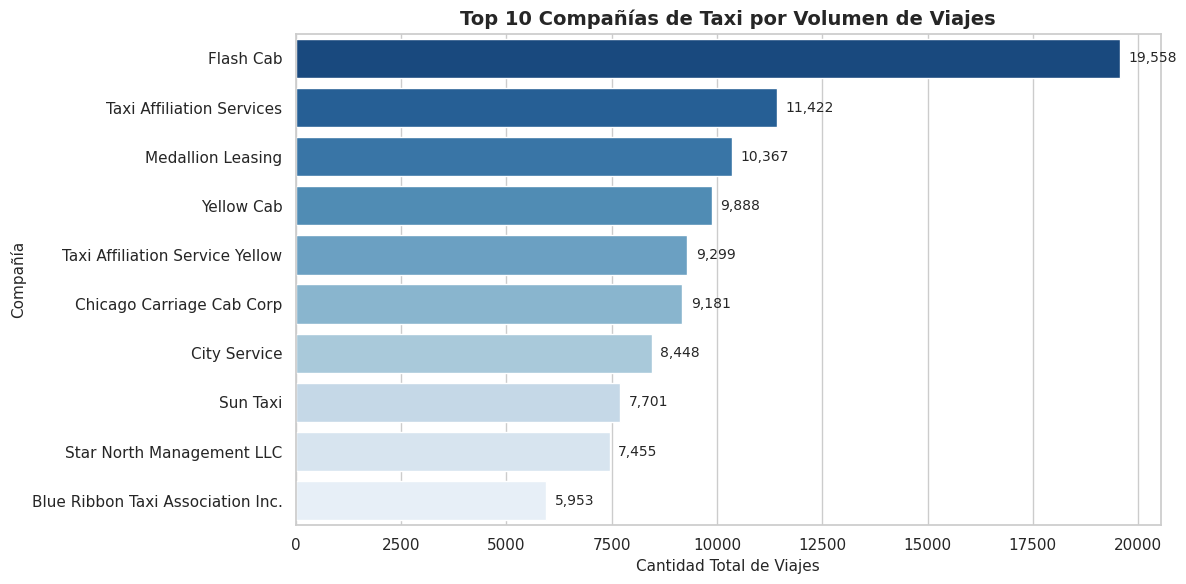

In [16]:
top_10_companies = df_companies.sort_values(by='trips_amount', ascending=False).head(10)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=top_10_companies,
    x='trips_amount',
    y='company_name',
    palette='Blues_r'
)

plt.title('Top 10 Compañías de Taxi por Volumen de Viajes', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad Total de Viajes', fontsize=11)
plt.ylabel('Compañía', fontsize=11)

# Inserción de etiquetas directas sobre las barras
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,}',
                (width + 200, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()


**Conclusiones del Gráfico 1:**
* **Liderazgo de mercado**: **Flash Cab** lidera de manera clara la industria con **19,558 viajes**, superando ampliamente a los demás competidores durante el periodo analizado.
* **Competencia secundaria**: **Taxi Affiliation Services** (11,422 viajes) y **Medallion Leased** (10,331 viajes) ocupan el segundo y tercer lugar, manteniendo niveles de demanda similares entre sí.
* **Implicación comercial**: La concentración del volumen en Flash Cab indica que Zuber debe desarrollar estrategias competitivas para atraer tanto a conductores como a usuarios en horas de mayor demanda.



#### Gráfico 2: Top 10 Barrios de Chicago por Promedio de Finalización de Viajes



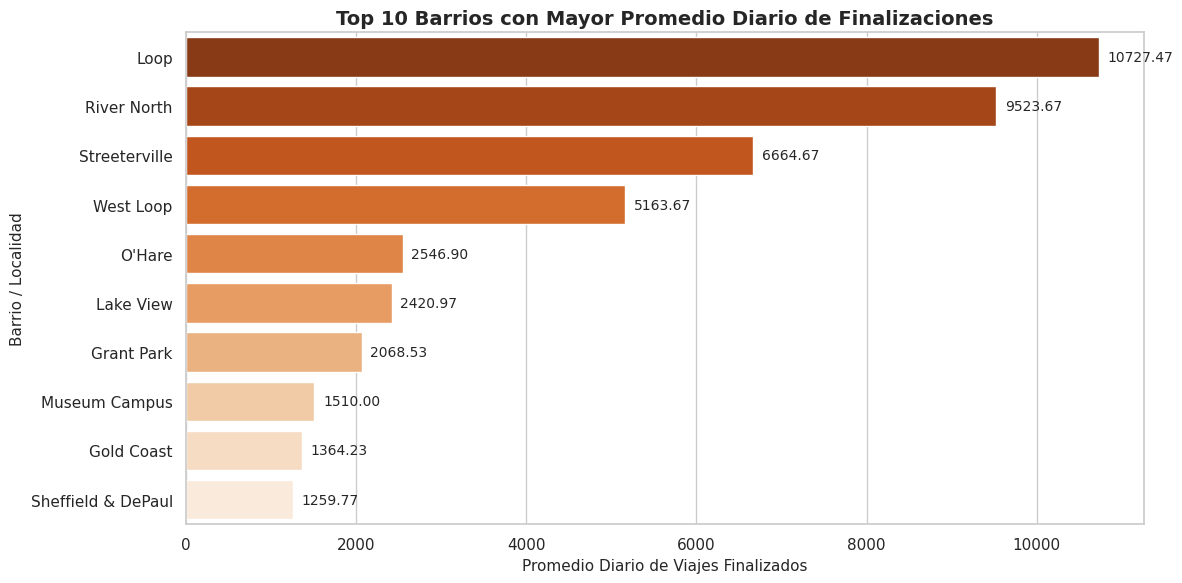

In [17]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=top_10_dropoffs,
    x='average_trips',
    y='dropoff_location_name',
    palette='Oranges_r'
)

plt.title('Top 10 Barrios con Mayor Promedio Diario de Finalizaciones', fontsize=14, fontweight='bold')
plt.xlabel('Promedio Diario de Viajes Finalizados', fontsize=11)
plt.ylabel('Barrio / Localidad', fontsize=11)

# Inserción de etiquetas directas sobre las barras
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.2f}',
                (width + 100, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

**Conclusiones del Gráfico 2:**
* **Concentración geográfica**: **Loop** (10,727.47 viajes) y **River North** (9,523.67 viajes) son los principales centros de destino en Chicago, concentrando la mayor actividad económica y turística de la ciudad.
* **Ruta de transporte clave**: El **Aeropuerto O'Hare** se sitúa en la quinta posición con 2,546.90 finalizaciones diarias. Representa un segmento clave debido a la mayor duración y rentabilidad por viaje.



## 3. Paso 5: Prueba de Hipótesis Estadística

Evaluamos si la duración promedio de los viajes en la ruta **Loop -> Aeropuerto Internacional O'Hare** cambia en los sábados lluviosos.

### 3.1 Planteamiento del Marco Experimental

* **Hipótesis Nula (H0)**: La duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare **es la misma** en sábados lluviosos y no lluviosos.
* **Hipótesis Alternativa (H1)**: La duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare **cambia** en sábados lluviosos.
* **Nivel de significación (alpha)**: **0.05** (5%).
* **Criterio de prueba**: **Prueba t de Student para dos muestras independientes** (`scipy.stats.ttest_ind`).  
  *Justificación*: Se comparan las medias de una variable continua (`duration_seconds`) proveniente de dos grupos independientes y excluyentes (sábados con clima `Good` vs. sábados con clima `Bad`).



### 3.2 Carga de Datos y Ejecución de la Prueba



In [18]:
import pandas as pd
from scipy import stats

# ---------------------------------------------------------
# Step 1: Carga y Exploración Inicial del Dataset de Viajes
# ---------------------------------------------------------
try:
    df_trips = pd.read_csv('/datasets/project_sql_result_07.csv')
except FileNotFoundError:
    df_trips = pd.read_csv('project_sql_result_07.csv')

print("--- Primeros 5 registros ---")
display(df_trips.head())

print("\n--- Información del Dataset ---")
df_trips.info()

print("\n--- Conteo de Valores Nulos ---")
print(df_trips.isna().sum())

print(f"\n--- Filas duplicadas iniciales: {df_trips.duplicated().sum()} ---")

# Eliminación de duplicados para evitar sobreestimar el tamaño muestral
df_trips = df_trips.drop_duplicates().reset_index(drop=True)
print(f"--- Filas duplicadas tras limpieza: {df_trips.duplicated().sum()} ---")

# ---------------------------------------------------------
# Step 2: Conversión y Validación de Fechas
# ---------------------------------------------------------
df_trips['start_ts'] = pd.to_datetime(df_trips['start_ts'])

# Confirmar que todos los registros correspondan a sábado (dayofweek == 5)
dias_semana = df_trips['start_ts'].dt.day_name().unique()
print(f"\nDías de la semana presentes en los datos: {dias_semana}")

# ---------------------------------------------------------
# Step 3: Detección y Tratamiento de Duraciones Iguales a 0
# ---------------------------------------------------------
trips_cero = (df_trips['duration_seconds'] == 0).sum()
print(f"\nNúmero de viajes con duration_seconds = 0: {trips_cero}")

# Justificación: Los viajes con duración 0 son registros anómalos/cancelados.
# Se filtran para no sesgar el cálculo de los tiempos promedio.
df_trips_clean = df_trips[df_trips['duration_seconds'] > 0].copy()

# ---------------------------------------------------------
# Step 4: Formación de Muestras e Inspección de Varianza (Levene)
# ---------------------------------------------------------
good_weather = df_trips_clean[df_trips_clean['weather_conditions'] == 'Good']['duration_seconds']
bad_weather = df_trips_clean[df_trips_clean['weather_conditions'] == 'Bad']['duration_seconds']

# Prueba de Levene para verificar homogeneidad de varianzas
stat_levene, p_value_levene = stats.levene(good_weather, bad_weather)

print(f"\nPrueba de Levene: p-value = {p_value_levene:.4e}")

# Justificación e interpretación de Levene
alpha = 0.05
if p_value_levene < alpha:
    equal_variances = False
    print("Interpretación Levene: Se rechaza la H0 de varianzas iguales (p < 0.05). Se usará equal_var=False en el t-test.")
else:
    equal_variances = True
    print("Interpretación Levene: No se rechaza la H0 de varianzas iguales. Se usará equal_var=True en el t-test.")

# ---------------------------------------------------------
# Step 5: Ejecución del Test t de Student
# ---------------------------------------------------------
results = stats.ttest_ind(good_weather, bad_weather, equal_var=equal_variances)

print("\n" + "="*50)
print("RESULTADOS DE LA PRUEBA T DE STUDENT")
print("="*50)
print(f"Muestra buen clima (Good): {len(good_weather)} viajes | Promedio: {good_weather.mean()/60:.2f} min")
print(f"Muestra mal clima (Bad):   {len(bad_weather)} viajes | Promedio: {bad_weather.mean()/60:.2f} min")
print(f"Diferencia en minutos:    {(bad_weather.mean() - good_weather.mean())/60:.2f} min")
print(f"Estadístico t:            {results.statistic:.4f}")
print(f"Valor p (p-value):        {results.pvalue:.4e}")
print("="*50)

if results.pvalue < alpha:
    print("Resultado: Se rechaza la hipótesis nula (H0).")
    print("Conclusión: Existe una diferencia estadísticamente significativa en la duración promedio de los viajes entre sábados lluviosos y no lluviosos.")
else:
    print("Resultado: No se rechaza la hipótesis nula (H0).")
    print("Conclusión: No hay suficiente evidencia estadística para afirmar un cambio en la duración promedio del viaje.")

--- Primeros 5 registros ---


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0



--- Información del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB

--- Conteo de Valores Nulos ---
start_ts              0
weather_conditions    0
duration_seconds      0
dtype: int64

--- Filas duplicadas iniciales: 197 ---
--- Filas duplicadas tras limpieza: 0 ---

Días de la semana presentes en los datos: ['Saturday']

Número de viajes con duration_seconds = 0: 6

Prueba de Levene: p-value = 8.1952e-01
Interpretación Levene: No se rechaza la H0 de varianzas iguales. Se usará equal_var=True en el t-test.

RESULTADOS DE LA PRUEBA T DE STUDENT
Muestra buen clima (Good): 717 viajes | Promedio: 34.15 min
Muestra mal clima (

## 4. Conclusiones Generales y Recomendaciones

### Resumen de Hallazgos

**1. Patrones del Mercado:**
* El mercado de taxis en Chicago presenta una alta concentración encabezada por **Flash Cab** (19,558 viajes).
* Los destinos con mayor demanda corresponden a las áreas comerciales y turísticas del centro (**Loop** con 10,727.47 finalizaciones promedio y **River North** con 9,523.67), mientras que el **Aeropuerto O'Hare** se posiciona como la quinta ruta clave con 2,546.90 finalizaciones diarias.

**2. Impacto Climático:**
* Tras limpiar el dataset (eliminando 197 filas duplicadas y 6 registros anómalos con `duration_seconds = 0`), la muestra final se compuso de **717 viajes en días despejados (Good)** y **148 viajes en días lluviosos (Bad)**.
* La prueba de homogeneidad de varianzas de Levene obtuvo un $p\text{-value} = 0.8195$ ($p > 0.05$), confirmando la igualdad de varianzas (`equal_var=True`).
* El **test t de Student** arrojó un **$p\text{-value} = 1.5394 \times 10^{-7}$**, el cual es muy inferior al nivel de significación ($\alpha = 0.05$). Por lo tanto, **se rechaza la hipótesis nula ($H_0$)**.
* Las condiciones meteorológicas adversas incrementan de forma estadísticamente significativa la duración promedio del viaje desde Loop hasta el Aeropuerto O'Hare los días sábado, pasando de **34.15 minutos** en días despejados a **40.15 minutos** en días lluviosos (una diferencia promedio de **6.00 minutos**).


### Recomendaciones Operativas para Zuber

* **Disponibilidad de flota:** Concentrar la flota de vehículos en los barrios **Loop** y **River North** durante horas pico para maximizar la ocupación de los conductores.
* **Ajuste de algoritmo por clima:** Implementar ajustes automáticos de +6 minutos en las estimaciones de tiempo de llegada (ETA) y activar tarifas dinámicas durante periodos de lluvia los días sábado para compensar el incremento de tráfico y mantener la rentabilidad del conductor ante la congestión vehicular.